# ASHRAE RP-1043: обучение и проверка TEP-комбинации


В этом ноутбуке рассматриваем модель из итоговой сборки `03_fused_index.ipynb`, адаптированную для датасета ASHRAE.
Содержание: загрузка датасета, разбиение на окна, разбиение нормы, стандартизация, обучение, калибровка порога, оценка 28 файлов
неисправностей, таблицы и графики. Сборка модели совпадает с итоговой сборкой


Используется существующий код исследовательской ветки:

- `prepare_ashrae_public.py` - загрузка зафиксированной CSV-копии;
- `data.ashrae.chiller_windows`, `normal_split`, `ChillerWindows` - окна и разбиения;
- `CanonicalVariateIndex`, `WindowMomentIndex`, `SlowFeatureIndex`, `TailMax`,
  `WithinRunEWMA` - готовые компоненты модели;
- `contiguous_groups` - границы непрерывных последовательностей;
- `run_ashrae_benchmark.empirical_threshold`, `metrics` - порог и метрики ASHRAE.

Новые реализации детекторов и новое обучение вспомогательных моделей не добавлены.
Две небольшие функции ниже только масштабируют ASHRAE-окна и согласуют их метаданные
с `WithinRunEWMA.score_batch`.


In [113]:
import importlib
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

INSTALL_MISSING_DEPENDENCIES = True


def find_project_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "src/industrial_novelty/data/ashrae.py").is_file():
            return candidate
    raise FileNotFoundError(
        "Запустите ноутбук из notebooks/ или корня проекта. "
        "В репозитории должен быть src/industrial_novelty/data/ashrae.py."
    )


PROJECT_ROOT = find_project_root()
required_files = [
    "scripts/prepare_ashrae_public.py",
    "scripts/run_ashrae_benchmark.py",
    "requirements-ashrae.txt",
]
absent = [
    str(PROJECT_ROOT / name)
    for name in required_files
    if not (PROJECT_ROOT / name).is_file()
]
if absent:
    raise FileNotFoundError(
        "В текущей копии проекта нет файлов ASHRAE:\n" + "\n".join(absent)
    )

# Локальные модули подключаются ДО установки дополнительных библиотек.
# prepare_ashrae_public находится в scripts/, это не пакет из PyPI.
local_paths = [str(PROJECT_ROOT / "src"), str(PROJECT_ROOT / "scripts")]
sys.path[:] = local_paths + [entry for entry in sys.path if entry not in local_paths]
importlib.invalidate_caches()
if importlib.util.find_spec("prepare_ashrae_public") is None:
    raise ModuleNotFoundError(
        f"Не удалось подключить {PROJECT_ROOT / 'scripts/prepare_ashrae_public.py'}"
    )

print("Python ядра:", sys.executable)
print("Проект:", PROJECT_ROOT)
print("Downloader:", importlib.util.find_spec("prepare_ashrae_public").origin)


def run_setup_command(command, purpose):
    result = subprocess.run(command, check=False, capture_output=True, text=True)
    if result.returncode:
        details = (result.stdout + "\n" + result.stderr).strip()
        raise RuntimeError(f"{purpose}\n{details[-5000:]}")
    return result.stdout.strip()


missing = [
    name
    for name in ("sklearn", "scipy", "threadpoolctl")
    if importlib.util.find_spec(name) is None
]
if missing:
    if not INSTALL_MISSING_DEPENDENCIES:
        raise ImportError(
            f"Не установлены {missing}. Включите INSTALL_MISSING_DEPENDENCIES "
            "или установите requirements-ashrae.txt в Python текущего ядра."
        )

    # find_spec('pip') недостаточно: pip может быть повреждённым namespace-пакетом.
    pip_check = subprocess.run(
        [sys.executable, "-m", "pip", "--version"],
        check=False,
        capture_output=True,
        text=True,
    )
    if pip_check.returncode:
        print("Восстанавливаем pip в Python текущего ядра...")
        run_setup_command(
            [sys.executable, "-m", "ensurepip", "--upgrade"],
            "Не удалось восстановить pip через ensurepip.",
        )
        run_setup_command(
            [sys.executable, "-m", "pip", "--version"],
            "После ensurepip pip по-прежнему недоступен.",
        )

    print("Устанавливаем ASHRAE-зависимости в Python текущего ядра...")
    run_setup_command(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-r",
            str(PROJECT_ROOT / "requirements-ashrae.txt"),
        ],
        "Не удалось установить requirements-ashrae.txt. Проверьте сообщение pip ниже.",
    )
    importlib.invalidate_caches()
    unresolved = [name for name in missing if importlib.util.find_spec(name) is None]
    if unresolved:
        raise ImportError(f"После установки не найдены библиотеки: {unresolved}")

print("Локальные модули и ASHRAE-зависимости готовы.")

Python ядра: D:\Best_proger_ever\3 sem\industrial-anomaly-detection\.venv\Scripts\python.exe
Проект: D:\Best_proger_ever\3 sem\industrial-anomaly-detection
Downloader: D:\Best_proger_ever\3 sem\industrial-anomaly-detection\scripts\prepare_ashrae_public.py
Локальные модули и ASHRAE-зависимости готовы.


In [114]:
import hashlib
import importlib.metadata
import json
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from prepare_ashrae_public import COMMIT as DATA_SOURCE_COMMIT
from prepare_ashrae_public import FILES as DATA_FILES
from run_ashrae_benchmark import empirical_threshold, metrics
from sklearn.metrics import precision_recall_curve, roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

from industrial_novelty import (
    CanonicalVariateIndex,
    SlowFeatureIndex,
    TailMax,
    WindowMomentIndex,
    WithinRunEWMA,
)
from industrial_novelty.data.ashrae import (
    CHANNELS,
    FAULTS,
    ChillerWindows,
    chiller_windows,
    normal_split,
)
from industrial_novelty.models.chiller_directions import contiguous_groups

plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110})
pd.set_option("display.max_rows", 40)
pd.set_option("display.precision", 4)
timings = {}
started_total = perf_counter()

## 1. Настройки эксперимента

`HELD_OUT_BAND=None` - блоковое разбиение с присутствием разных температурных
полос в обучении. Установить `HELD_OUT_BAND=50`, чтобы проверить новый режим:
полоса 50 °F будет исключена из fit/reference/calibration и оставлена для test.
Разбиение задаётся существующей `normal_split`, а не случайным перемешиванием окон.

Длина 48 и шаг 6 соответствуют поздней проверке переноса. Уставки 40/45/50 °F
не являются полным набором эксплуатационных режимов. При изменении настроек
результат станет новым экспериментом, его не следует автоматически приравнивать
к историческим таблицам. Пять seeds можно исследовать отдельными последовательными
запусками, меняя `SEED`; по умолчанию выполняется один запуск.

In [115]:
WINDOW = 48
STRIDE = 6
BLOCK_SIZE = 180
EMBARGO = 12
SEED = 0
MODEL_SEED = 0
HELD_OUT_BAND = None  # None, 40, 45 или 50
TARGET_FPR = 0.15
EWMA_LAMBDA = 0.2
N_THREADS = 2
DOWNLOAD_IF_MISSING = True
SAVE_RESULTS = True

# Переменные окружения нужны только для запуска с внешним хранилищем данных.
# Без них используются обычные каталоги текущего репозитория.
DATA_DIR = Path(
    os.environ.get("ASHRAE_DATA_DIR", PROJECT_ROOT / "data/raw/ashrae_public")
)
PROTOCOL = "blocked" if HELD_OUT_BAND is None else f"hold{HELD_OUT_BAND}"
OUTPUT_BASE = Path(
    os.environ.get("ASHRAE_OUTPUT_DIR", PROJECT_ROOT / "results/ashrae_tep_notebook")
)
OUTPUT_DIR = OUTPUT_BASE / f"{PROTOCOL}_w{WINDOW}_stride{STRIDE}_seed{SEED}"

assert WINDOW >= 2 and STRIDE >= 1
assert HELD_OUT_BAND in (None, 40, 45, 50)
assert 0 < TARGET_FPR < 1
assert 0 < EWMA_LAMBDA <= 1
print("Данные:", DATA_DIR)
print("Новые результаты:", OUTPUT_DIR)
print("Протокол:", PROTOCOL)

Данные: D:\Best_proger_ever\3 sem\industrial-anomaly-detection\data\raw\ashrae_public
Новые результаты: D:\Best_proger_ever\3 sem\industrial-anomaly-detection\results\ashrae_tep_notebook\blocked_w48_stride6_seed0
Протокол: blocked


## 2. Загрузка исходных CSV и проверка версии



In [116]:
t0 = perf_counter()
expected_manifest_path = PROJECT_ROOT / "results/ashrae_2026-11-04/data_manifest.json"
expected_manifest = json.loads(expected_manifest_path.read_text(encoding="utf-8"))
if expected_manifest["source_commit"] != DATA_SOURCE_COMMIT:
    raise ValueError("Версия downloader не совпадает с историческим data_manifest.")
missing_files = [name for name in DATA_FILES if not (DATA_DIR / name).is_file()]
if missing_files:
    if not DOWNLOAD_IF_MISSING:
        raise FileNotFoundError(f"Отсутствуют ASHRAE CSV: {missing_files}")
    subprocess.run(
        [
            sys.executable,
            str(PROJECT_ROOT / "scripts/prepare_ashrae_public.py"),
            "--data",
            str(DATA_DIR),
            "--output",
            str(OUTPUT_DIR / "data_audit"),
        ],
        check=True,
    )

verified = []
for record in expected_manifest["files"]:
    path = DATA_DIR / record["file"]
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if digest != record["sha256"]:
        raise ValueError(f"Другая версия исходных данных: {path.name}")
    verified.append({"file": path.name, "sha256": digest, "bytes": path.stat().st_size})
verified_files = pd.DataFrame(verified)
normal_hashes = verified_files.loc[
    verified_files.file.str.startswith("normal"), "sha256"
]
assert normal_hashes.nunique() == 1
timings["download_and_verify_seconds"] = perf_counter() - t0
print(f"Проверены все {len(verified_files)} CSV. Четыре файла нормы одинаковы.")
display(pd.read_csv(DATA_DIR / "normal10.csv").loc[:, list(CHANNELS)].head())

Проверены все 32 CSV. Четыре файла нормы одинаковы.


,TWE_set,TWCI,TEI,TEO,TWEI,TWEO,TCI,TCO,TWCO,kW,...,TRC_sub,T_suc,Tsh_suc,TR_dis,Tsh_dis,Amps,TO_sump,TO_feed,PO_feed,PO_net
0,50,64.2,62.28,63.20,62.3,63.1,64.28,65.14,65.0,1.6800e-45,...,0.0,80.8,17.8,71.1,8.0,0,103.7,85.3,57.1,0.0
1,50,64.2,62.24,63.20,62.3,63.1,64.28,65.14,65.1,1.6800e-45,...,0.0,80.8,17.8,70.9,8.0,0,103.5,85.4,57.1,0.0
2,50,65.3,62.24,63.16,63.3,63.3,64.32,65.10,64.7,1.6800e-45,...,0.0,80.8,17.8,71.1,5.9,0,103.3,85.3,56.6,0.0
3,50,65.1,62.52,63.25,64.8,63.7,64.57,65.10,65.4,1.6800e-45,...,0.0,81.2,16.7,71.1,6.6,0,103.1,85.3,59.1,0.0
4,50,64.5,63.01,63.49,64.4,64.7,64.69,65.14,64.7,1.6800e-45,...,0.0,81.3,17.6,70.9,7.0,0,102.8,85.3,58.6,0.0


## 3. Временные окна и разделение нормальных данных

`chiller_windows` выбирает 26 каналов, отбрасывает нерабочие/невалидные точки,
нарезает окна внутри блоков и температурных полос. Окно не пересекает удалённую
строку. Блок - 180 исходных строк, на краях отбрасывается по 12 строк.

`normal_split` отделяет fit, reference, calibration и test. Reference сохраняется
для совместимости с историческим протоколом, но именно этой TEP-сборке не нужен:
компоненты, хвостовые масштабы и центр/std EWMA оцениваются по fit, порог - по
calibration. Reference не присоединяется к fit. Неисправные файлы при обучении
и подборе порога не используются.

In [117]:
t0 = perf_counter()
normal = chiller_windows(
    DATA_DIR / "normal10.csv",
    window=WINDOW,
    stride=STRIDE,
    block_size=BLOCK_SIZE,
    embargo=EMBARGO,
)
parts, block_roles = normal_split(normal, SEED, held_out_band=HELD_OUT_BAND)

# Проверяем не только номера блоков, но и отсутствие общих исходных строк.
used_rows = {}
for role, batch in parts.items():
    rows = set()
    for start, end in batch.meta[["row_start", "row_end"]].itertuples(
        index=False, name=None
    ):
        rows.update(range(int(start), int(end) + 1))
    used_rows[role] = rows
for i, role in enumerate(used_rows):
    for other in list(used_rows)[i + 1 :]:
        assert used_rows[role].isdisjoint(used_rows[other]), (role, other)
if HELD_OUT_BAND is not None:
    assert all(
        not batch.meta.temperature_band.eq(HELD_OUT_BAND).any()
        for role, batch in parts.items()
        if role != "test"
    )
    assert parts["test"].meta.temperature_band.eq(HELD_OUT_BAND).all()

counts = pd.DataFrame(
    [
        {
            "split": role,
            "n_windows": len(batch.X),
            "n_blocks": batch.meta.block.nunique(),
            "window_size": batch.X.shape[1],
            "n_channels": batch.X.shape[2],
            "unique_source_rows": len(used_rows[role]),
        }
        for role, batch in parts.items()
    ]
)
display(counts)
print("Общих исходных строк между частями нет.")
timings["normal_windows_and_split_seconds"] = perf_counter() - t0

,split,n_windows,n_blocks,window_size,n_channels,unique_source_rows
0,fit,248,14,48,26,2118
1,reference,91,5,48,26,756
2,calibration,81,5,48,26,738
3,test,91,5,48,26,756


Общих исходных строк между частями нет.


## 4. Стандартизация и согласование метаданных

Как в историческом ASHRAE-transfer, `StandardScaler` обучается только на отсчётах
fit-окон. Перекрывающиеся окна дают повторные вхождения некоторых обучающих строк;
это соответствует сохранённому эксперименту и не переносит test-данные в fit.

`WithinRunEWMA.score_batch` ожидает `simulation_run` и `sample_end`. У ASHRAE вместо
них — блоки и номера исходных строк. Адаптер ниже использует `contiguous_groups`:
каждый непрерывный участок становится отдельной последовательностью, а `row_end`
передаётся как `sample_end`. **Это технические идентификаторы участков, не независимые
физические прогоны.** Само сглаживание выполняет существующий `WithinRunEWMA`.

In [118]:
t0 = perf_counter()
scaler = StandardScaler().fit(parts["fit"].X.reshape(-1, len(CHANNELS)))


def scaled_windows(batch):
    values = scaler.transform(batch.X.reshape(-1, len(CHANNELS)))
    return values.reshape(batch.X.shape).astype(np.float32)


def score_chiller(model, batch):
    groups = contiguous_groups(batch.meta, stride=STRIDE)
    sequence_ids = np.empty(len(batch.X), dtype=np.int64)
    for sequence_id, indices in enumerate(groups):
        sequence_ids[indices] = sequence_id
    meta = batch.meta.assign(
        simulation_run=sequence_ids,
        sample_end=batch.meta.row_end.to_numpy(),
    )
    adapted = ChillerWindows(scaled_windows(batch), meta)
    return model.score_batch(adapted)


X_fit = scaled_windows(parts["fit"])
assert X_fit.shape[1:] == (WINDOW, len(CHANNELS))
assert np.isfinite(X_fit).all()
timings["scaling_seconds"] = perf_counter() - t0
print("Вход модели:", X_fit.shape, X_fit.dtype)

Вход модели: (248, 48, 26) float32


## 5. Обучение TEP-комбинации на норме ASHRAE

Используется тот же набор классов, что и в третьем ноутбуке. CVA оценивает связи
половин окна, Moments — средние/std, Slow Features — медленные нормальные связи.
TailMax объединяет нормированные скоры, EWMA сглаживает итоговый скор с λ=0.2.
Это статистические оценки и линейная алгебра, обучение по эпохам здесь отсутствует.

`alpha=0.01` внутри компонентов и TailMax задаёт хвостовые масштабы по обучающей
норме. Он **не равен** эксплуатационному `TARGET_FPR`: окончательный порог отдельно
выбирается по calibration после EWMA. Все параметры фиксируются до оценки отказов.

In [119]:
model = WithinRunEWMA(
    TailMax(
        (
            CanonicalVariateIndex(seed=MODEL_SEED),
            WindowMomentIndex(),
            SlowFeatureIndex(),
        )
    ),
    lam=EWMA_LAMBDA,
)

t0 = perf_counter()
with threadpool_limits(limits=N_THREADS):
    model.fit(X_fit)
timings["model_fit_seconds"] = perf_counter() - t0

print(model)
print(f"Обучение всей комбинации: {timings['model_fit_seconds']:.3f} с")
print("Хвостовые масштабы TailMax:", model.inner.scales_)
print("Центр/std для EWMA:", model.center_, model.spread_)

WithinRunEWMA(TailMax, lam=0.2)
Обучение всей комбинации: 0.266 с
Хвостовые масштабы TailMax: [1.46054078 1.         1.        ]
Центр/std для EWMA: 0.8802606284491362 0.10645935111874204


## 6. Калибровка и проверка на нормальном test

Повторно используется ASHRAE-калибратор: тревога при `score > threshold`.
Calibration и normal test оцениваются отдельно; порог не подстраивается по test.
`normal_fpr` — доля ложных окон. `normal_block_alarm_rate` — доля искусственных
блоков хотя бы с одной тревогой. Эти показатели не взаимозаменяемы.

Из-за зависимости окон и смены режима фактическая test-FPR может превышать номинал.
Ни окно, ни искусственный блок не являются независимой повторной экспериментальной
кампанией. Точная задержка обнаружения в минутах для этой копии не вычисляется.

In [120]:
t0 = perf_counter()
with threadpool_limits(limits=N_THREADS):
    calibration_scores = score_chiller(model, parts["calibration"])
    normal_scores = score_chiller(model, parts["test"])
threshold = empirical_threshold(calibration_scores, TARGET_FPR)
normal_fpr = float(np.mean(normal_scores > threshold))
normal_block_alarm_rate = float(
    pd.DataFrame(
        {"block": parts["test"].meta.block, "alarm": normal_scores > threshold}
    )
    .groupby("block")
    .alarm.any()
    .mean()
)
normal_result = pd.DataFrame(
    [
        {
            "model": "CVA + Moments + Slow Features + TailMax + EWMA",
            "protocol": PROTOCOL,
            "seed": SEED,
            "target_fpr": TARGET_FPR,
            "threshold": threshold,
            "calibration_windows": len(calibration_scores),
            "normal_test_windows": len(normal_scores),
            "normal_test_fpr": normal_fpr,
            "normal_block_alarm_rate": normal_block_alarm_rate,
        }
    ]
)
display(normal_result)
timings["calibration_and_normal_test_seconds"] = perf_counter() - t0

,model,protocol,seed,target_fpr,threshold,calibration_windows,normal_test_windows,normal_test_fpr,normal_block_alarm_rate
0,CVA + Moments + Slow Features + TailMax + EWMA,blocked,0,0.15,909.6844,81,91,0.0,0.0


## 7. Проверка всех семи неисправностей на четырёх уровнях

Теперь, после обучения и фиксации порога, открываются 28 неисправных файлов.
SL1 — слабый уровень, SL4 — сильный; одинаковый номер уровня не означает одинаковый
физический процент воздействия для разных неисправностей. При holdout-режиме
в тест допускается только выбранная температурная полоса.

Из существующей `metrics` берутся AUROC, balanced AP, recall и normal FPR.
Balanced AP рассчитана при искусственных весах normal/fault 50/50 и не равна
precision в реальной эксплуатации с редкими отказами. Дополнительно используется
стандартизованная pAUC@5% из sklearn (случайный уровень 0.5).

In [121]:
t0 = perf_counter()
per_fault_rows = []
fault_batches = {}
fault_scores = {}
FAULT_NAMES = {
    "cf": "Загрязнение конденсатора",
    "eo": "Избыток масла",
    "fwc": "Снижение расхода конденсатора",
    "fwe": "Снижение расхода испарителя",
    "nc": "Неконденсирующиеся газы",
    "rl": "Утечка хладагента",
    "ro": "Избыточная заправка",
}
with threadpool_limits(limits=N_THREADS):
    for fault in FAULTS:
        for severity in (1, 2, 3, 4):
            filename = f"{fault}{severity * 10}.csv"
            batch = chiller_windows(
                DATA_DIR / filename,
                window=WINDOW,
                stride=STRIDE,
                block_size=BLOCK_SIZE,
                embargo=EMBARGO,
            )
            if HELD_OUT_BAND is not None:
                batch = batch.take(
                    np.flatnonzero(
                        batch.meta.temperature_band.to_numpy() == HELD_OUT_BAND
                    )
                )
            if not len(batch.X):
                raise ValueError(
                    f"Нет допустимых тестовых окон: {filename}, {PROTOCOL}"
                )
            values = score_chiller(model, batch)
            y = np.r_[np.zeros(len(normal_scores)), np.ones(len(values))]
            pooled_scores = np.r_[normal_scores, values]
            block_alarm_rate = float(
                pd.DataFrame(
                    {
                        "block": batch.meta.block,
                        "alarm": values > threshold,
                    }
                )
                .groupby("block")
                .alarm.any()
                .mean()
            )
            per_fault_rows.append(
                {
                    "fault": fault,
                    "fault_name": FAULT_NAMES[fault],
                    "severity": severity,
                    "n_windows": len(values),
                    "threshold": threshold,
                    **metrics(normal_scores, values, threshold),
                    "pauc05": roc_auc_score(y, pooled_scores, max_fpr=0.05),
                    "fault_block_alarm_rate": block_alarm_rate,
                }
            )
            fault_batches[fault, severity] = batch
            fault_scores[fault, severity] = values
        print(f"Проверено семейство: {fault}")

per_fault = pd.DataFrame(per_fault_rows)
assert len(per_fault) == len(FAULTS) * 4
timings["fault_loading_windows_and_test_seconds"] = perf_counter() - t0

Проверено семейство: cf
Проверено семейство: eo
Проверено семейство: fwc
Проверено семейство: fwe
Проверено семейство: nc
Проверено семейство: rl
Проверено семейство: ro


## 8. Итоговые таблицы

Первая таблица похожа по назначению на таблицу третьего ноутбука, но единица
оценки здесь — **окно ASHRAE**. `recall` не является долей обнаруженных независимых
прогонов. Вместо неизвестных onset и задержки показаны recall окон и доля искусственных
блоков с тревогой. Нормальная FPR одинакова во всех строках, поскольку нормальный
test и порог общие. Полные неокруглённые значения сохраняются в CSV.

In [122]:
columns = [
    "fault",
    "fault_name",
    "severity",
    "n_windows",
    "auroc",
    "balanced_ap",
    "pauc05",
    "recall",
    "normal_fpr",
    "fault_block_alarm_rate",
]
display(
    per_fault[columns]
    .style.format(
        {
            "auroc": "{:.3f}",
            "balanced_ap": "{:.3f}",
            "pauc05": "{:.3f}",
            "recall": "{:.1%}",
            "normal_fpr": "{:.1%}",
            "fault_block_alarm_rate": "{:.1%}",
        }
    )
    .hide(axis="index")
)

metric_columns = [
    "auroc",
    "balanced_ap",
    "pauc05",
    "recall",
    "normal_fpr",
    "fault_block_alarm_rate",
]
summary_by_severity = per_fault.groupby("severity")[metric_columns].mean().reset_index()
summary_by_fault = (
    per_fault.groupby(["fault", "fault_name"])[metric_columns].mean().reset_index()
)
display(
    Markdown("**Макроусреднение по семи семействам, отдельно для каждого уровня:**")
)
display(summary_by_severity)
display(
    Markdown("**Макроусреднение по четырём уровням, отдельно для каждого семейства:**")
)
display(summary_by_fault)
sl1_result = summary_by_severity.set_index("severity").loc[1]
display(
    Markdown(
        f"**SL1, seed={SEED}: AUROC {sl1_result.auroc:.3f}; "
        f"recall {sl1_result.recall:.1%}; normal FPR {normal_fpr:.1%}.** "
        "Это один блоковый split, не среднее пяти независимых экспериментов."
    )
)

fault,fault_name,severity,n_windows,auroc,balanced_ap,pauc05,recall,normal_fpr,fault_block_alarm_rate
cf,Загрязнение конденсатора,1,493,1.000,1.000,1.000,94.7%,0.0%,100.0%
cf,Загрязнение конденсатора,2,516,1.000,1.000,0.997,95.0%,0.0%,100.0%
cf,Загрязнение конденсатора,3,515,1.000,1.000,0.999,95.5%,0.0%,100.0%
cf,Загрязнение конденсатора,4,520,1.000,1.000,1.000,99.2%,0.0%,100.0%
eo,Избыток масла,1,505,0.747,0.689,0.511,2.8%,0.0%,3.4%
eo,Избыток масла,2,522,0.908,0.894,0.625,2.7%,0.0%,3.4%
eo,Избыток масла,3,524,0.964,0.968,0.857,21.2%,0.0%,44.8%
eo,Избыток масла,4,503,0.990,0.991,0.948,67.8%,0.0%,100.0%
fwc,Снижение расхода конденсатора,1,527,0.993,0.994,0.962,76.1%,0.0%,96.6%
fwc,Снижение расхода конденсатора,2,503,1.000,1.000,1.000,99.8%,0.0%,100.0%


**Макроусреднение по семи семействам, отдельно для каждого уровня:**

,severity,auroc,balanced_ap,pauc05,recall,normal_fpr,fault_block_alarm_rate
0,1,0.8417,0.8249,0.7727,0.4729,0.0,0.5616
1,2,0.8660,0.8573,0.7873,0.4524,0.0,0.4877
2,3,0.9008,0.8976,0.8286,0.4824,0.0,0.5517
3,4,0.9398,0.9382,0.8713,0.6553,0.0,0.7340


**Макроусреднение по четырём уровням, отдельно для каждого семейства:**

,fault,fault_name,auroc,balanced_ap,pauc05,recall,normal_fpr,fault_block_alarm_rate
0,cf,Загрязнение конденсатора,0.9999,0.9999,0.9990,0.9611,0.0,1.0000
1,eo,Избыток масла,0.9023,0.8854,0.7353,0.2361,0.0,0.3793
2,fwc,Снижение расхода конденсатора,0.9983,0.9984,0.9906,0.9397,0.0,0.9914
3,fwe,Снижение расхода испарителя,1.0000,1.0000,1.0000,1.0000,0.0,1.0000
4,nc,Неконденсирующиеся газы,0.9807,0.9829,0.9220,0.4204,0.0,0.6207
5,rl,Утечка хладагента,0.6387,0.6193,0.5144,0.0261,0.0,0.0431
6,ro,Избыточная заправка,0.6896,0.6705,0.5437,0.0267,0.0,0.0517


**SL1, seed=0: AUROC 0.842; recall 47.3%; normal FPR 0.0%.** Это один блоковый split, не среднее пяти независимых экспериментов.

При текущем пороге, доля ложных тревог близка к нулю, при этом неисправность с избытком масла, утечкой масла, избыточной заправкой плохо обнаруживается

## 9. Графики реальных скоров и качества

Все графики ниже построены по скорам этого нового запуска. Для временного примера
по умолчанию выбрана трудная неисправность — слабая утечка хладагента (`rl`, SL1).
Можно поменять `PLOT_FAULT` и `PLOT_SEVERITY`. Ось X — номер исходной строки,
не физическое время. Линии не соединяют разные блоки или разрывы. Метки семьи
относятся к файлу целиком: положение действительного onset не предполагается.

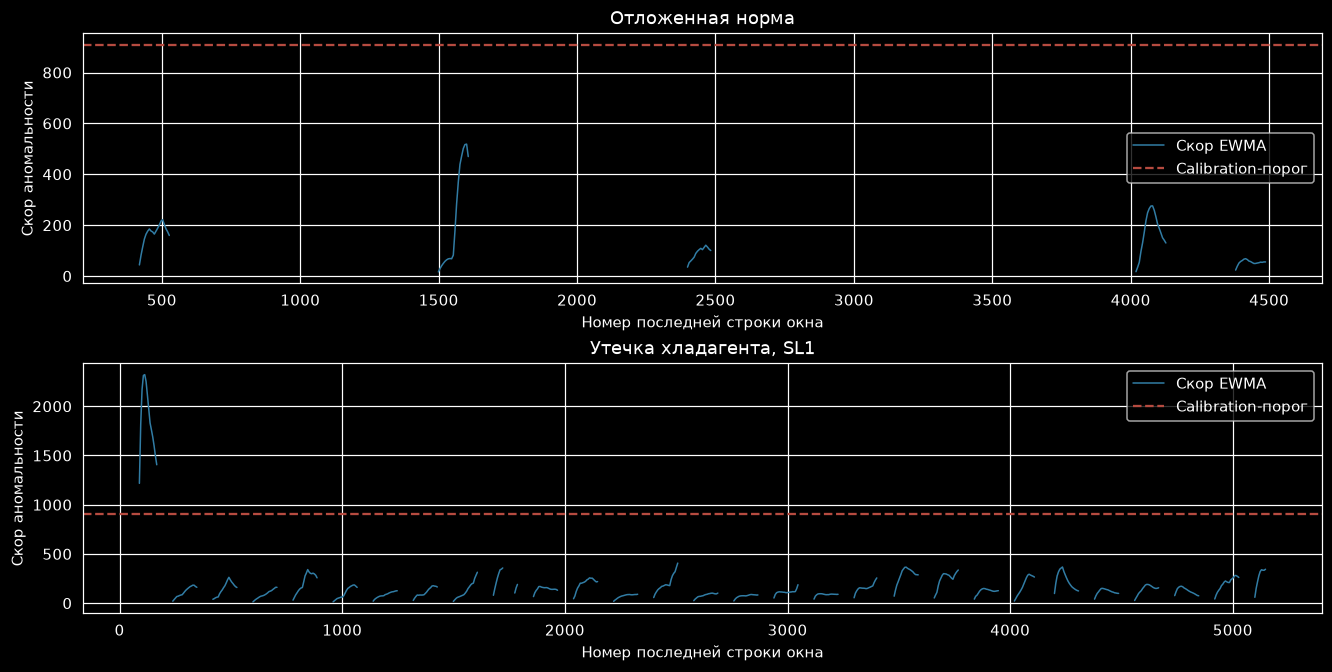

In [123]:
PLOT_FAULT = "rl"
PLOT_SEVERITY = 1
fig, axes = plt.subplots(2, 1, figsize=(12, 6), layout="constrained")
for ax, batch, values, title in [
    (axes[0], parts["test"], normal_scores, "Отложенная норма"),
    (
        axes[1],
        fault_batches[PLOT_FAULT, PLOT_SEVERITY],
        fault_scores[PLOT_FAULT, PLOT_SEVERITY],
        f"{FAULT_NAMES[PLOT_FAULT]}, SL{PLOT_SEVERITY}",
    ),
]:
    for i, indices in enumerate(contiguous_groups(batch.meta, stride=STRIDE)):
        ax.plot(
            batch.meta.row_end.iloc[indices],
            values[indices],
            color="#317ca4",
            lw=1,
            label="Скор EWMA" if i == 0 else None,
        )
    ax.axhline(threshold, color="#b64b40", ls="--", label="Calibration-порог")
    ax.set(
        title=title, xlabel="Номер последней строки окна", ylabel="Скор аномальности"
    )
    ax.legend()
plt.show()

При выбранном пороге детектор не выдаёт ложных тревог на отложенной норме, однако чувствительность к слабой утечке хладагента ограничена. Основная часть неисправной записи получает скоры, сопоставимые с нормальными.

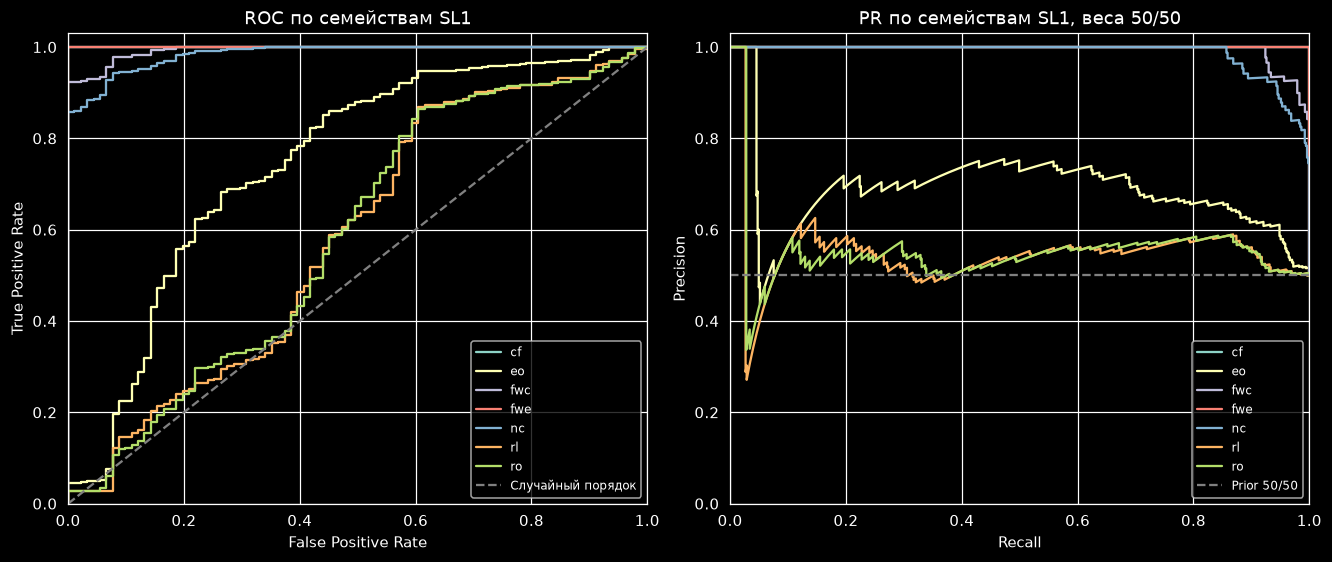

In [124]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for fault in FAULTS:
    values = fault_scores[fault, 1]
    y = np.r_[np.zeros(len(normal_scores)), np.ones(len(values))]
    scores = np.r_[normal_scores, values]
    fpr, tpr, _ = roc_curve(y, scores)
    weights = np.r_[
        np.full(len(normal_scores), 0.5 / len(normal_scores)),
        np.full(len(values), 0.5 / len(values)),
    ]
    precision, recall, _ = precision_recall_curve(y, scores, sample_weight=weights)
    axes[0].plot(fpr, tpr, label=fault)
    axes[1].plot(recall, precision, label=fault)
axes[0].plot([0, 1], [0, 1], color="gray", ls="--", label="Случайный порядок")
axes[1].axhline(0.5, color="gray", ls="--", label="Prior 50/50")
axes[0].set(
    title="ROC по семействам SL1",
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
)
axes[1].set(
    title="PR по семействам SL1, веса 50/50", xlabel="Recall", ylabel="Precision"
)
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.03)
    ax.legend(fontsize=8)
plt.show()

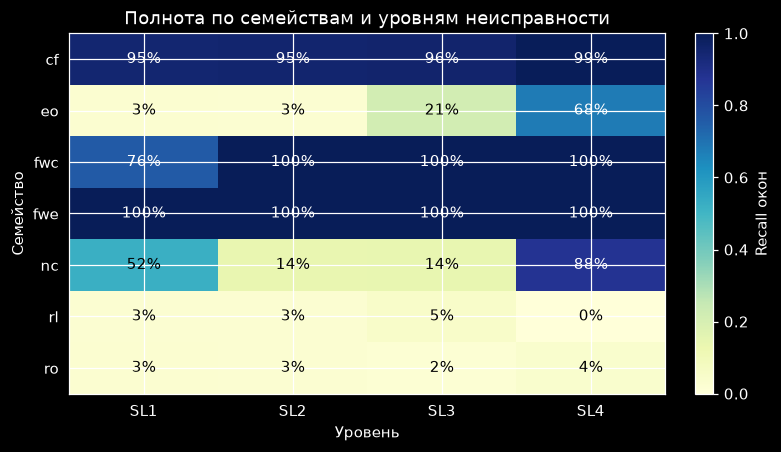

In [125]:
recall_map = per_fault.pivot(index="fault", columns="severity", values="recall")
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
im = ax.imshow(recall_map, vmin=0, vmax=1, cmap="YlGnBu", aspect="auto")
ax.set(
    xticks=range(4),
    xticklabels=["SL1", "SL2", "SL3", "SL4"],
    yticks=range(len(recall_map)),
    yticklabels=recall_map.index,
    title="Полнота по семействам и уровням неисправности",
    xlabel="Уровень",
    ylabel="Семейство",
)
for i in range(len(recall_map)):
    for j in range(4):
        value = recall_map.iloc[i, j]
        ax.text(
            j,
            i,
            f"{value:.0%}",
            ha="center",
            va="center",
            color="white" if value > 0.65 else "black",
        )
fig.colorbar(im, ax=ax, label="Recall окон")
plt.show()

## 10. Вывод

Подход, разработанный на TEP, работает на ASHRAE избирательно: одни слабые неисправности он различает хорошо, другие значительно хуже.

Загрязнение конденсатора и снижение расходов воды хорошо отделяются от нормы. Неконденсирующиеся газы также обнаруживаются достаточно уверенно. Избыток масла сложнее: повышение полноты требует больше ложных тревог. Для слабой утечки и избыточной заправки хладагентом разделение недостаточное.

Одним снижением порога проблему полностью не решить: оно увеличит чувствительность, но одновременно повысит число ложных тревог.